# Thesis Fig. 2 — kernel–target matrix

Reproduction of Tepper (2026), Fig. 2 (thesis PDF p. 34; printed p. 27), panel by panel.

> Columns are target classes (Gaussian PSD, polynomial, chaotic harmonic, piecewise, narrowband); rows are kernel
> families (broad Gaussian, narrow Gaussian, point, box, Gabor). Bottom: log10 relative MSE with the best kernel per
> class starred. Right: effective rank r_k of each kernel.

**Panels:** A targets · B kernels · C reconstructions (5×5) · D effective ranks · E error heatmap.

**Acceptance (spec 6A.6):** no single kernel is best for all classes; the best kernel per class matches the figure's
stars (σ=0.29, σ=0.29, point, box, Gabor).

**Parameters [D11]:** the thesis text does not list them. N and the kernel labels are read from the figure; the
rest is set in `configs/thesis/fig2.yaml`. Kernels are compared at **equal spectral energy** K0 (eq. 7.3; the
rank-vs-strength trade-off of §2.2 only exists under a budget). With unit-integral normalization instead, the point
kernel wins every class (recorded in REPORT.md). Readout = ridge (eq. 3.13) with T_obs = N; λ in D10 units.

**Calibration disclosure:** λ = 30 is the value from the panel-F sweep that reproduces the stars, so the star match
is a one-parameter calibration, not an independent check. The independent content: a single λ reproduces all five
stars together, and the error magnitudes fall in the figure's colorbar range (log10 rel. MSE ≈ −0.2 to −2.2).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seqnet.thesis as th
from seqnet.thesis.figures import load_config, save_data, load_data, save_figure, record_checks, style

style()
FIG = "fig2"
cfg = load_config(FIG)
N, decay = cfg["N"], cfg["decay"]
ring = th.Ring(N)
sched = th.Schedule(N, 1)
K_LABELS, T_LABELS = list(cfg["kernels"]), list(cfg["targets"])
cfg

{'N': 128,
 'energy': 'equal',
 'K0_reference': {'family': 'gaussian', 'sigma': 0.3},
 'decay': 30.0,
 'decay_sweep': [0.01, 0.1, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0],
 'rank_eps': 0.05,
 'seed': 7,
 'kernels': {'Gaussian sigma=1': ['gaussian', {'sigma': 1.0}],
  'Gaussian sigma=0.29': ['gaussian', {'sigma': 0.29}],
  'Point sigma=0.025': ['gaussian', {'sigma': 0.025}],
  'Box R=1.2': ['box', {'R': 1.2}],
  'Gabor xi0=8': ['gabor', {'sigma': 0.29, 'xi0': 8.0}]},
 'targets': {'Gaussian PSD': {'kind': 'gaussian_psd', 'beta': 0.02},
  'Polynomial': {'kind': 'polynomial', 's': 1.5},
  'Chaotic harmonic': {'kind': 'flat', 'B': 48},
  'Piecewise': {'kind': 'piecewise', 'n_steps': 6},
  'Narrowband': {'kind': 'narrowband', 'xi0': 8.0, 'ell': 1.5}},
 'figure_ranks': [5, 17, 128, 37, 39],
 'figure_best': ['Gaussian sigma=0.29',
  'Gaussian sigma=0.29',
  'Point sigma=0.025',
  'Box R=1.2',
  'Gabor xi0=8']}

## Panel A — target signals

One fixed draw per class (random phases, Thesis A4), sampled at the N bump positions. The piecewise class is a
deterministic piecewise-constant function with random breakpoints and levels.

In [2]:
def make_target(spec, rng):
    kind, M = spec["kind"], N // 2 - 1
    if kind == "piecewise":
        cuts = np.sort(rng.choice(np.arange(1, N), spec["n_steps"] - 1, replace=False))
        levels = rng.normal(size=spec["n_steps"])
        return np.repeat(levels, np.diff(np.r_[0, cuts, N])).astype(float)
    if kind == "gaussian_psd":
        tc = th.TargetClass.gaussian_psd(M, beta=spec["beta"])
    elif kind == "polynomial":
        tc = th.TargetClass.polynomial(M, s=spec["s"])
    elif kind == "flat":
        tc = th.TargetClass.flat(M, B=spec["B"])
    elif kind == "narrowband":
        tc = th.TargetClass.narrowband(M, xi0=spec["xi0"], ell=spec["ell"])
    return tc.sample(rng, N, sched.positions)

rng = np.random.default_rng(cfg["seed"])
Y = np.stack([make_target(cfg["targets"][t], rng) for t in T_LABELS])
save_data(FIG, "A_targets", params={"targets": cfg["targets"], "seed": cfg["seed"]}, Y=Y, c=sched.positions)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig2/A_targets.npz')

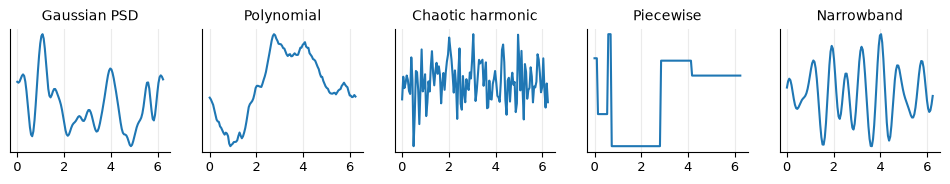

In [3]:
d = load_data(FIG, "A_targets")
fig, axs = plt.subplots(1, 5, figsize=(12, 1.6), sharex=True)
for ax, y, lab in zip(axs, d["Y"], T_LABELS):
    ax.plot(d["c"], y, color="tab:blue"); ax.set_title(lab); ax.set_yticks([])
save_figure(FIG, "A_targets", fig); plt.show()

## Panel B — kernel profiles

App. D families on the N-neuron ring, then rescaled to the common energy K0 = N Σ_i k_i² (D10 units).

In [4]:
ref = cfg["K0_reference"]
K0 = th.Kernel.from_family(ref["family"], N, **{k: v for k, v in ref.items() if k != "family"}).energy()
kernels = [th.Kernel.from_family(fam, N, **par) for fam, par in cfg["kernels"].values()]
if cfg["energy"] == "equal":  # rescale each kernel to energy K0 (Thesis eq. 7.3)
    kernels = [th.Kernel(values=k.values * np.sqrt(K0 / k.energy()), name=k.name, params=k.params) for k in kernels]
Kv = np.stack([k.values for k in kernels])
save_data(FIG, "B_kernels", params={"kernels": cfg["kernels"], "K0": K0, "energy": cfg["energy"]}, K=Kv, r=ring.centred_positions)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig2/B_kernels.npz')

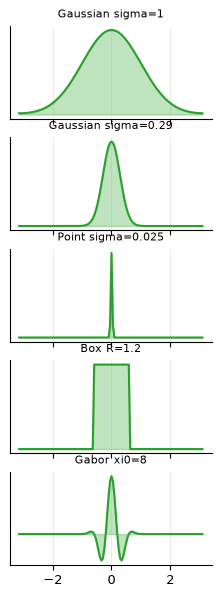

In [5]:
d = load_data(FIG, "B_kernels")
order = np.argsort(d["r"])
fig, axs = plt.subplots(5, 1, figsize=(2.6, 7), sharex=True)
for ax, kv, lab in zip(axs, d["K"], K_LABELS):
    ax.plot(d["r"][order], kv[order], color="tab:green"); ax.fill_between(d["r"][order], kv[order], alpha=0.3, color="tab:green")
    ax.set_title(lab, fontsize=8); ax.set_yticks([])
save_figure(FIG, "B_kernels", fig); plt.show()

## Panel C — reconstructions

Ridge readout (eq. 3.13) for every kernel–target pair; relative MSE = Σ(ŷ − y)² / Σ y² over the N positions.

In [6]:
X_all = [th.design_matrix(k, sched) for k in kernels]
YH = np.zeros((5, 5, N)); REL = np.zeros((5, 5))
for i, X in enumerate(X_all):
    for j, y in enumerate(Y):
        yh = X @ th.ridge_readout(X, y, decay)
        YH[i, j] = yh
        REL[i, j] = np.sum((yh - y) ** 2) / np.sum(y ** 2)
save_data(FIG, "C_reconstructions", params={"decay": decay}, YH=YH, Y=Y, REL=REL, c=sched.positions)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig2/C_reconstructions.npz')

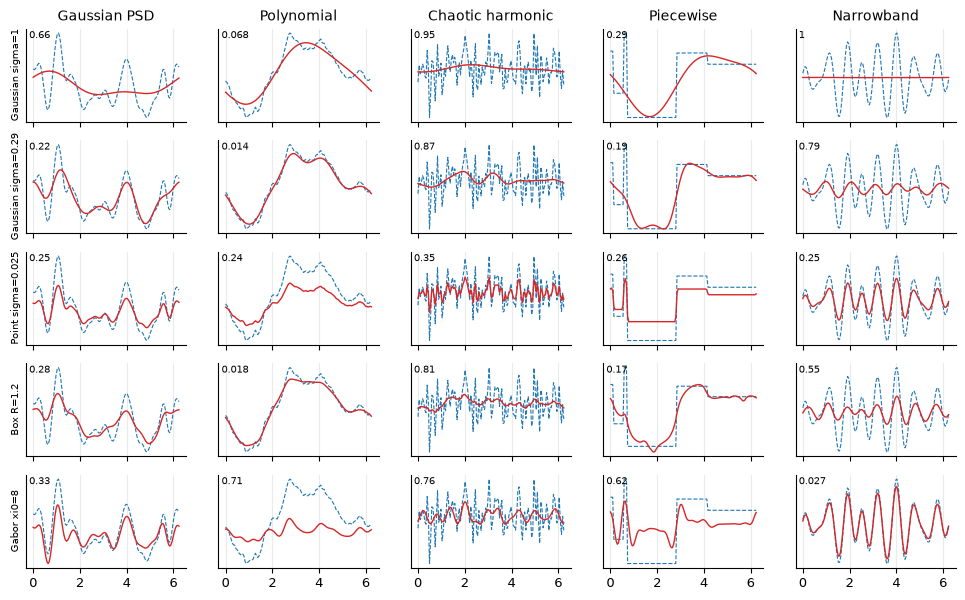

In [7]:
d = load_data(FIG, "C_reconstructions")
fig, axs = plt.subplots(5, 5, figsize=(12, 7), sharex=True)
for i in range(5):
    for j in range(5):
        ax = axs[i, j]
        ax.plot(d["c"], d["Y"][j], "--", color="tab:blue", lw=0.8)
        ax.plot(d["c"], d["YH"][i, j], color="tab:red", lw=1)
        ax.set_yticks([]); ax.text(0.02, 0.9, f"{d['REL'][i, j]:.2g}", transform=ax.transAxes, fontsize=7)
        if i == 0: ax.set_title(T_LABELS[j])
        if j == 0: ax.set_ylabel(K_LABELS[i], fontsize=7)
save_figure(FIG, "C_reconstructions", fig); plt.show()

## Panel D — effective rank

Eq. 4.8 counts all N signed modes with |k̂_m|/|k̂_0| > ε. The Gabor's DC coefficient is ≈ 0, so it is also given
relative to the spectral maximum.

In [8]:
eps = cfg["rank_eps"]
rank_dc = np.array([k.effective_rank(eps, "dc") if abs(k.spectrum()[0]) > 1e-9 * np.abs(k.spectrum()).max() else -1 for k in kernels])
rank_max = np.array([k.effective_rank(eps, "max") for k in kernels])
save_data(FIG, "D_rank", params={"eps": eps}, rank_dc=rank_dc, rank_max=rank_max, figure=np.array(cfg["figure_ranks"]))

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig2/D_rank.npz')

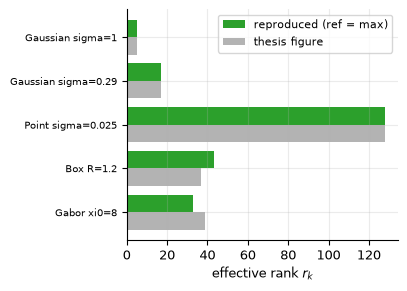

ref=dc : [  5  17 128  43  37]
ref=max: [  5  17 128  43  33]
figure : [  5  17 128  37  39]


In [9]:
d = load_data(FIG, "D_rank")
fig, ax = plt.subplots(figsize=(3.5, 3))
yy = np.arange(5)[::-1]
ax.barh(yy + 0.2, d["rank_max"], 0.4, color="tab:green", label="reproduced (ref = max)")
ax.barh(yy - 0.2, d["figure"], 0.4, color="0.7", label="thesis figure")
ax.set_yticks(yy, K_LABELS, fontsize=7); ax.set_xlabel("effective rank $r_k$"); ax.legend()
save_figure(FIG, "D_rank", fig); plt.show()
print("ref=dc :", d["rank_dc"]); print("ref=max:", d["rank_max"]); print("figure :", d["figure"])

## Panel E — log10 relative MSE, best kernel per class starred

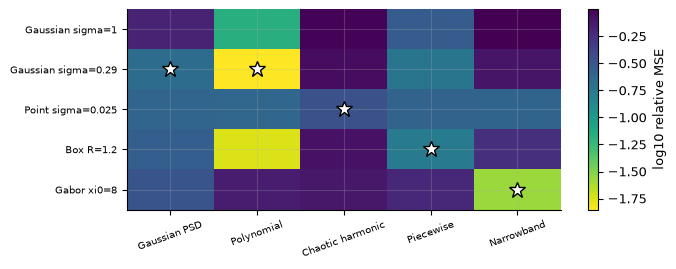

In [10]:
d = load_data(FIG, "C_reconstructions")
L = np.log10(d["REL"])
fig, ax = plt.subplots(figsize=(7, 2.6))
im = ax.imshow(L, cmap="viridis_r", aspect="auto")
best = L.argmin(0)
for j, i in enumerate(best):
    ax.plot(j, i, "*", ms=12, mfc="white", mec="k")
ax.set_xticks(range(5), T_LABELS, rotation=20, fontsize=7); ax.set_yticks(range(5), K_LABELS, fontsize=7)
fig.colorbar(im, ax=ax, label="log10 relative MSE")
save_figure(FIG, "E_heatmap", fig); plt.show()

## Panel F (added) — best kernel per class against λ

Not in the thesis figure. Shows how the stars depend on λ at equal energy, which is the basis of the λ calibration.

In [11]:
lams = np.array(cfg["decay_sweep"])
REL_L = np.zeros((lams.size, 5, 5))
for a, lam in enumerate(lams):
    for i, X in enumerate(X_all):
        for j, y in enumerate(Y):
            REL_L[a, i, j] = np.sum((X @ th.ridge_readout(X, y, lam) - y) ** 2) / np.sum(y ** 2)
save_data(FIG, "F_lambda_sweep", params={"decay_sweep": cfg["decay_sweep"]}, lams=lams, REL=REL_L)

WindowsPath('C:/Users/max/Documents/phd-work/results/thesis/data/fig2/F_lambda_sweep.npz')

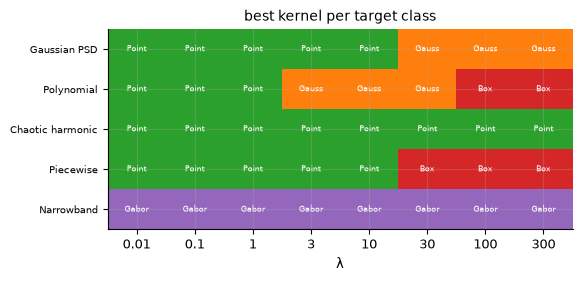

In [12]:
d = load_data(FIG, "F_lambda_sweep")
best = d["REL"].argmin(1)  # (n_lambda, 5 targets)
fig, ax = plt.subplots(figsize=(6, 2.6))
im = ax.imshow(best.T, cmap="tab10", vmin=0, vmax=9, aspect="auto")
ax.set_xticks(range(len(d["lams"])), [f"{l:g}" for l in d["lams"]]); ax.set_xlabel("λ")
ax.set_yticks(range(5), T_LABELS, fontsize=7)
for a in range(best.shape[0]):
    for j in range(5):
        ax.text(a, j, K_LABELS[best[a, j]].split()[0][:5] + ("" if "sigma=1" not in K_LABELS[best[a, j]] else "1"), ha="center", va="center", fontsize=6, color="w")
ax.set_title("best kernel per target class")
save_figure(FIG, "F_lambda_sweep", fig); plt.show()

## Acceptance

In [13]:
d = load_data(FIG, "C_reconstructions")
best = [K_LABELS[i] for i in d["REL"].argmin(0)]
match = [b == f for b, f in zip(best, cfg["figure_best"])]
checks = [
    {"item": "no single kernel best for all classes", "criterion": "#distinct best kernels > 1",
     "value": len(set(best)), "passed": len(set(best)) > 1},
    {"item": "best kernel per class matches figure stars (lambda calibrated, see panel F)", "criterion": "5/5 classes",
     "value": f"{sum(match)}/5: " + ", ".join(f"{t}: {b}" for t, b in zip(T_LABELS, best)), "passed": all(match)},
]
L = np.log10(d["REL"])
checks.append({"item": "error range comparable to figure colorbar", "criterion": "log10 rel. MSE within [-2.5, 0.1]",
               "value": [float(L.min()), float(L.max())], "passed": bool(L.min() > -2.5 and L.max() < 0.1)})
record_checks(FIG, checks)
for c in checks: print(("PASS " if c["passed"] else "FAIL ") + c["item"], "->", c["value"])

PASS no single kernel best for all classes -> 4
PASS best kernel per class matches figure stars (lambda calibrated, see panel F) -> 5/5: Gaussian PSD: Gaussian sigma=0.29, Polynomial: Gaussian sigma=0.29, Chaotic harmonic: Point sigma=0.025, Piecewise: Box R=1.2, Narrowband: Gabor xi0=8
PASS error range comparable to figure colorbar -> [-1.8513402882778434, -3.466069303098678e-05]
